# Loft25 Customer Returns — Modular Analysis & Predictive Modeling

This notebook analyzes customer orders, order lines, and return costs for **Loft25** (*Gardenista* & *Game Over*) and builds leak-free, imbalance-aware return prediction models (**Logistic Regression**, **XGBoost**, and **TabNet**).

**Notebook Structure (Modular System):**
- **Module 1** (`1.1`–`1.4`): Environment setup, auto-path detection (Colab & local), and data loading
- **Module 2** (`2.1`–`2.4`): Data quality audit, cleaning, and anomaly handling
- **Module 3** (`3.1`–`3.2`): Proper relational joins (preserving composite keys and avoiding target leakage)
- **Module 4** (`4.1`–`4.7`): Exploratory Data Analysis (KPIs, brands, channels, seasonality, couriers, return costs, SKUs)
- **Module 5** (`5.1`–`5.6`): Pre-purchase feature engineering, customer-grouped splitting, and preprocessing
- **Module 6** (`6.1`–`6.4`): Imbalance-aware model training & validation-based threshold tuning
- **Module 7** (`7.1`–`7.4`): Model comparison, ROC/PR curves, feature importance, and business takeaways

# Module 1: Environment Setup & Data Loading

Configure dependencies, import core packages, locate the 4 source files (automatically supporting both Google Colab `/content` and local directories), and verify loaded dimensions.

### 1.1 Install Optional Packages

Checks for packages that may not be pre-installed (especially `pytorch-tabnet`, `xgboost`, `openpyxl`, and `seaborn`) and installs only what is missing.

- **Why:** Keeps the notebook self-contained on Google Colab or fresh local environments without reinstalling already-present libraries.

In [1]:
import importlib.util
import subprocess
import sys

required = {
    "openpyxl": "openpyxl",
    "seaborn": "seaborn",
    "xgboost": "xgboost",
    "pytorch_tabnet": "pytorch-tabnet",
}

for module_name, pip_name in required.items():
    if importlib.util.find_spec(module_name) is None:
        print(f"Installing {pip_name}...")
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", pip_name])
print("All required packages are available.")

All required packages are available.


### 1.2 Core Imports & Global Configuration

Imports core data manipulation, visualization, and modeling utilities, and sets reproducible styling and random seeds.

- **Key Constant:** `RANDOM_STATE = 42` is reused across all splits and models for reproducibility.

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.4f}".format)
warnings.filterwarnings("ignore", category=UserWarning)

### 1.3 Locate Data Directory & Load All 4 Datasets

Automatically locates the dataset folder (checking the current working directory first, then Google Colab's `/content` directory) and loads all four source tables.

- **Outputs:** `customer_orders_df`, `order_lines_df`, `returns_df`, `returns_by_sku_df`.

In [3]:
CANDIDATE_DIRS = [Path("."), Path("/content")]
DATA_DIR = next(
    (d for d in CANDIDATE_DIRS if (d / "Loft25_BCU_04_P4_order_lines.csv").exists()),
    None,
)
if DATA_DIR is None:
    raise FileNotFoundError("Place the 4 dataset files in the working directory or /content.")

customer_orders_df = pd.read_excel(DATA_DIR / "Project 4 & 5 - customer orders.xlsx")
returns_df = pd.read_excel(DATA_DIR / "Project 4 & 5 - Returns.xlsx")
order_lines_df = pd.read_csv(DATA_DIR / "Loft25_BCU_04_P4_order_lines.csv")
returns_by_sku_df = pd.read_csv(DATA_DIR / "Loft25_BCU_05_P4_returns_by_SKU.csv")

print(f"Loaded datasets from: {DATA_DIR.resolve()}")

Loaded datasets from: C:\Users\promi\Downloads\jakir


### 1.4 Dataset Inventory & Schema Overview

Displays row counts, column counts, and column headers for all four loaded DataFrames so we can verify exact column names before cleaning or joining.

In [4]:
datasets = {
    "customer_orders_df": customer_orders_df,
    "order_lines_df": order_lines_df,
    "returns_df": returns_df,
    "returns_by_sku_df": returns_by_sku_df,
}

summary_rows = [
    {"Dataset": name, "Rows": df.shape[0], "Cols": df.shape[1], "Columns": ", ".join(df.columns)}
    for name, df in datasets.items()
]
display(pd.DataFrame(summary_rows))

,Dataset,Rows,Cols,Columns
0,customer_orders_df,31410,6,"Order ref, Customer ref, Order date, Brand, Ch..."
1,order_lines_df,34305,15,"Order ref, Order date, Month, Brand, Channel, ..."
2,returns_df,1523,20,"Order ref, Customer ref, SKU, Brand, Channel, ..."
3,returns_by_sku_df,1458,10,"SKU, Brand, Units sold, Units returned, Units ..."


# Module 2: Data Quality Audit & Cleaning

Inspect missing values, duplicates, date formatting, cross-table key integrity, and pricing/discount anomalies before analysis or modeling.

### 2.1 Missing Value & Exact Duplicate Audit

Scans every dataset for null values and exact duplicate rows.

- **Expected Finding:** Only `returns_df` contains nulls—specifically a 100% empty separator column (`Unnamed: 14`).

In [5]:
for name, df in datasets.items():
    nulls = df.isnull().sum()
    nulls = nulls[nulls > 0]
    dups = df.duplicated().sum()
    print(f"=== {name} | exact duplicates: {dups} ===")
    if len(nulls) > 0:
        display(pd.DataFrame({"Missing Count": nulls, "Missing %": (nulls / len(df) * 100).round(2)}))
    else:
        print("  No missing values.\n")

=== customer_orders_df | exact duplicates: 0 ===
  No missing values.

=== order_lines_df | exact duplicates: 0 ===
  No missing values.

=== returns_df | exact duplicates: 0 ===


,Missing Count,Missing %
Unnamed: 14,1523,100.0000


=== returns_by_sku_df | exact duplicates: 0 ===
  No missing values.



### 2.2 Drop Empty Columns & Standardize Date Types

Removes empty `Unnamed:` columns from `returns_df` and converts all date fields across tables to proper `datetime64` format for consistent temporal analysis.

In [6]:
unnamed_cols = [c for c in returns_df.columns if str(c).startswith("Unnamed:")]
if unnamed_cols:
    returns_df = returns_df.drop(columns=unnamed_cols)
    print(f"Dropped empty columns from returns_df: {unnamed_cols}")

order_lines_df["Order date"] = pd.to_datetime(order_lines_df["Order date"])
customer_orders_df["Order date"] = pd.to_datetime(customer_orders_df["Order date"])
returns_df["Order date"] = pd.to_datetime(returns_df["Order date"])
returns_df["Return date"] = pd.to_datetime(returns_df["Return date"])

print("Updated returns_df shape:", returns_df.shape)
print("Order date span:", order_lines_df["Order date"].min().date(), "to", order_lines_df["Order date"].max().date())

Dropped empty columns from returns_df: ['Unnamed: 14']
Updated returns_df shape: (1523, 19)
Order date span: 2025-01-05 to 2026-09-30


### 2.3 Cross-Table Key Integrity & Anomaly Inspection

Checks join key uniqueness and surfaces known dataset anomalies:
1. Whether `('Order ref', 'SKU')` is unique in both `order_lines_df` and `returns_df`.
2. Returned order lines in `order_lines_df` (`1,533`) vs. rows in `returns_df` (`1,523`) — the 10 missing rows are £0-value items.
3. Rows with `Line discount > 100` (3 rows at 200%) and `Unit price inc VAT == 0` (724 rows).

In [7]:
ol_key_dups = order_lines_df.duplicated(subset=["Order ref", "SKU"]).sum()
ret_key_dups = returns_df.duplicated(subset=["Order ref", "SKU"]).sum()
orders_overlap = set(order_lines_df["Order ref"]) == set(customer_orders_df["Order ref"])

ol_ret_keys = set(zip(order_lines_df.loc[order_lines_df["Returned"] == 1, "Order ref"],
                      order_lines_df.loc[order_lines_df["Returned"] == 1, "SKU"]))
rd_keys = set(zip(returns_df["Order ref"], returns_df["SKU"]))
missing_in_returns = ol_ret_keys - rd_keys

print(f"Duplicate (Order ref, SKU) -> order_lines: {ol_key_dups}, returns_df: {ret_key_dups}")
print(f"Exact Order ref match (order_lines == customer_orders): {orders_overlap}")
print(f"Returned lines in order_lines but missing in returns_df: {len(missing_in_returns)}")
print(f"Rows with Line discount > 100: {(order_lines_df['Line discount'] > 100).sum()}")
print(f"Rows with Unit price inc VAT == 0: {(order_lines_df['Unit price inc VAT'] == 0).sum()}")

Duplicate (Order ref, SKU) -> order_lines: 0, returns_df: 0


Exact Order ref match (order_lines == customer_orders): True
Returned lines in order_lines but missing in returns_df: 10
Rows with Line discount > 100: 3
Rows with Unit price inc VAT == 0: 724


### 2.4 Clean Discount Outliers & Add Zero-Value Flag

Preserves raw columns while creating two clean helper fields on `order_lines_df`:
- `Line_discount_clean`: clips anomalous values (`200`) into the valid percentage range `[0, 100]`.
- `Is_zero_value`: binary flag marking £0-priced replacement/manual/100%-promo lines.

In [8]:
order_lines_df["Line_discount_clean"] = order_lines_df["Line discount"].clip(lower=0, upper=100)
order_lines_df["Is_zero_value"] = (order_lines_df["Unit price inc VAT"] == 0).astype(int)

print("Line_discount_clean range:",
      order_lines_df["Line_discount_clean"].min(), "to", order_lines_df["Line_discount_clean"].max())
print("Zero-value line count:", order_lines_df["Is_zero_value"].sum())

Line_discount_clean range: 0.0 to 100.0
Zero-value line count: 724


# Module 3: Relational Merging

Join the normalized tables on their verified primary keys (`Order ref` and `['Order ref', 'SKU']`) while strictly separating EDA tables from ML feature tables to prevent target leakage.

### 3.1 Merge Order Lines with Customer Orders (Pre-Purchase Master)

Left-joins `customer_orders_df` onto `order_lines_df` using `'Order ref'` to attach `Customer ref` and `Postcode area` (excluding overlapping columns like `Brand`, `Channel`, and `Order date` to avoid `_x`/`_y` suffix clutter).

- **Output:** `master_df` (34,305 rows — exact 1-to-1 preservation of order lines, safe for ML feature engineering).

In [9]:
cust_cols = ["Order ref", "Customer ref", "Postcode area"]
master_df = order_lines_df.merge(
    customer_orders_df[cust_cols],
    on="Order ref",
    how="left",
    validate="many_to_one",
)

assert len(master_df) == len(order_lines_df), "Row count changed after merge!"
print("master_df shape:", master_df.shape)
display(master_df[["Order ref", "Customer ref", "Order date", "Brand", "Channel", "Postcode area", "SKU", "Returned"]].head(5))

master_df shape: (34305, 19)


,Order ref,Customer ref,Order date,Brand,Channel,Postcode area,SKU,Returned
0,O000020,C000010,2025-01-09,Gardenista,Website (Shopify),NE10,GP G71 Steamer Harvest Green,0
1,O000019,C000009,2025-01-09,Gardenista,Amazon,BS49,PLT E12 Harvest Grey,1
2,O000024,C000014,2025-01-11,Gardenista,eBay,HA6,GP G45 B398 Grey,0
3,O000025,C000015,2025-01-11,Gardenista,Amazon,LS3,LGP10 Harvest Green,0
4,O000026,C000016,2025-01-11,Gardenista,eBay,B43,DCC PU Coated Green,0


### 3.2 Create EDA Table with Return Details (Composite Key Join)

Left-joins post-return details from `returns_df` onto `master_df` using the composite key `['Order ref', 'SKU']`.

- **Important:** Using `'Order ref'` alone would cause a many-to-many explosion (1,523 return lines span 1,433 orders).
- **Leakage Guardrail:** `eda_df` and `returns_by_sku_df` contain post-return / full-dataset outcomes and are used **exclusively in Module 4 (EDA)**, never as ML input features.

In [10]:
ret_detail_cols = [
    "Order ref", "SKU", "Return date", "Days to return", "Return reason",
    "Customer feedback", "Return shipping cost", "Unit cost of goods",
    "Scrapped", "Write-off cost", "Total return cost",
]
eda_df = master_df.merge(
    returns_df[ret_detail_cols],
    on=["Order ref", "SKU"],
    how="left",
    validate="one_to_one",
)

print("eda_df shape:", eda_df.shape)
print("Matched return detail rows:", eda_df["Return reason"].notna().sum())

eda_df shape: (34305, 28)
Matched return detail rows: 1523


# Module 4: Exploratory Data Analysis (EDA)

Quantify return rates and financial impact across brands, channels, months, couriers, return reasons, and SKUs.

### 4.1 Overall Return KPIs & Financial Impact

Computes top-level operational and financial KPIs across all order lines and recorded returns, distinguishing gross revenue, refunded revenue, and direct operational return costs (`shipping + write-off`).

In [11]:
kpis = {
    "Total Order Lines": f"{len(master_df):,}",
    "Distinct Orders": f"{master_df['Order ref'].nunique():,}",
    "Distinct Customers": f"{master_df['Customer ref'].nunique():,}",
    "Line Return Rate": f"{master_df['Returned'].mean() * 100:.2f}%",
    "Order Return Rate": f"{master_df.groupby('Order ref')['Returned'].max().mean() * 100:.2f}%",
    "Unit Return Rate": f"{master_df['Units returned'].sum() / master_df['Qty'].sum() * 100:.2f}%",
    "Gross Sales Value (inc VAT)": f"£{master_df['Line value inc VAT'].sum():,.2f}",
    "Total Refunded Value": f"£{master_df['Refund amount'].sum():,.2f}",
    "Total Operational Return Cost": f"£{returns_df['Total return cost'].sum():,.2f}",
    "Return Scrap Rate": f"{(returns_df['Scrapped'] == 'Yes').mean() * 100:.2f}%",
}
display(pd.DataFrame(list(kpis.items()), columns=["Metric", "Value"]))

,Metric,Value
0,Total Order Lines,"34,305"
1,Distinct Orders,"31,410"
2,Distinct Customers,"22,854"
3,Line Return Rate,4.47%
4,Order Return Rate,4.59%
5,Unit Return Rate,4.83%
6,Gross Sales Value (inc VAT),"£1,622,434.24"
7,Total Refunded Value,"£79,405.56"
8,Total Operational Return Cost,"£16,317.26"
9,Return Scrap Rate,29.61%


### 4.2 Brand Performance & Return Rate Comparison

Compares *Gardenista* vs. *Game Over* using both distinct orders (`nunique`) and order lines (`count`), avoiding the common mistake of labeling line counts as order counts.

,Brand,Order_Lines,Distinct_Orders,Return_Rate_Pct,Avg_Line_Value
0,Game Over,5065,4347,2.0336,62.8597
1,Gardenista,29240,27089,4.8906,44.5982


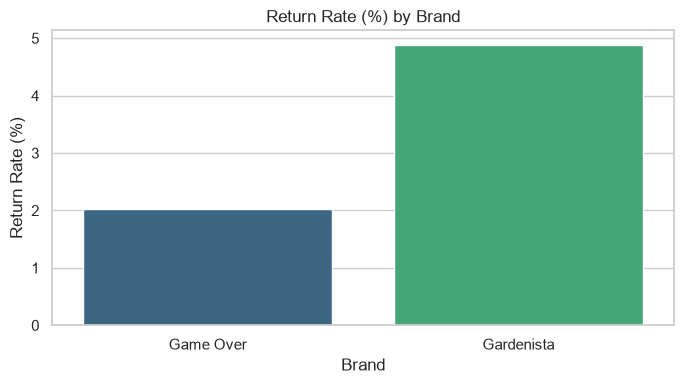

In [12]:
brand_eda = (
    master_df.groupby("Brand", as_index=False)
    .agg(
        Order_Lines=("Order ref", "count"),
        Distinct_Orders=("Order ref", "nunique"),
        Return_Rate_Pct=("Returned", lambda s: s.mean() * 100),
        Avg_Line_Value=("Line value inc VAT", "mean"),
    )
)
display(brand_eda)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(data=brand_eda, x="Brand", y="Return_Rate_Pct", hue="Brand", palette="viridis", legend=False, ax=ax)
ax.set_title("Return Rate (%) by Brand")
ax.set_ylabel("Return Rate (%)")
plt.tight_layout()
plt.show()

### 4.3 Channel Performance with Sample-Size Context

Evaluates return rates and average order line values per sales channel, annotating bar labels with sample size `n` so tiny channels (such as `Mirakl MP`, `n=11`) are not misinterpreted as large-scale trends.

,Channel,Order_Lines,Distinct_Orders,Returned_Lines,Return_Rate_Pct,Avg_Line_Value
0,Amazon,21678,20207,945,4.3593,47.1735
6,Website (Shopify),7047,5985,273,3.8740,51.1511
4,The Range,3492,3252,226,6.4719,48.3497
7,eBay,1399,1309,57,4.0743,45.2366
1,Direct/Manual,332,313,5,1.5060,0.9213
5,TikTok Shop,297,285,20,6.7340,15.7193
3,TEMU EU,49,49,3,6.1224,38.2459
2,Mirakl MP,11,10,4,36.3636,34.0173


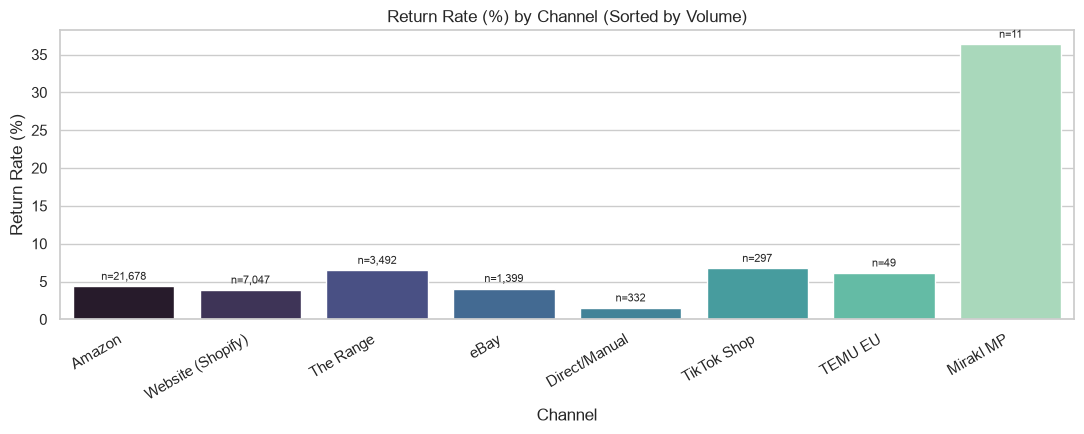

In [13]:
channel_eda = (
    master_df.groupby("Channel", as_index=False)
    .agg(
        Order_Lines=("Order ref", "count"),
        Distinct_Orders=("Order ref", "nunique"),
        Returned_Lines=("Returned", "sum"),
        Return_Rate_Pct=("Returned", lambda s: s.mean() * 100),
        Avg_Line_Value=("Line value inc VAT", "mean"),
    )
    .sort_values("Order_Lines", ascending=False)
)
display(channel_eda)

fig, ax = plt.subplots(figsize=(11, 4.5))
sns.barplot(data=channel_eda, x="Channel", y="Return_Rate_Pct", hue="Channel", palette="mako", legend=False, ax=ax)
for patch, n in zip(ax.patches, channel_eda["Order_Lines"]):
    ax.annotate(f"n={n:,}", (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=8, xytext=(0, 3), textcoords="offset points")
ax.set_title("Return Rate (%) by Channel (Sorted by Volume)")
ax.set_ylabel("Return Rate (%)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

### 4.4 Monthly Volume & Return Rate Seasonality by Brand

Plots monthly order lines and return rates over the 21-month window (`2025-01` to `2026-09`), highlighting *Gardenista*'s spring/summer surge and *Game Over*'s entry in July 2025 with a sharp Q4 gifting peak.

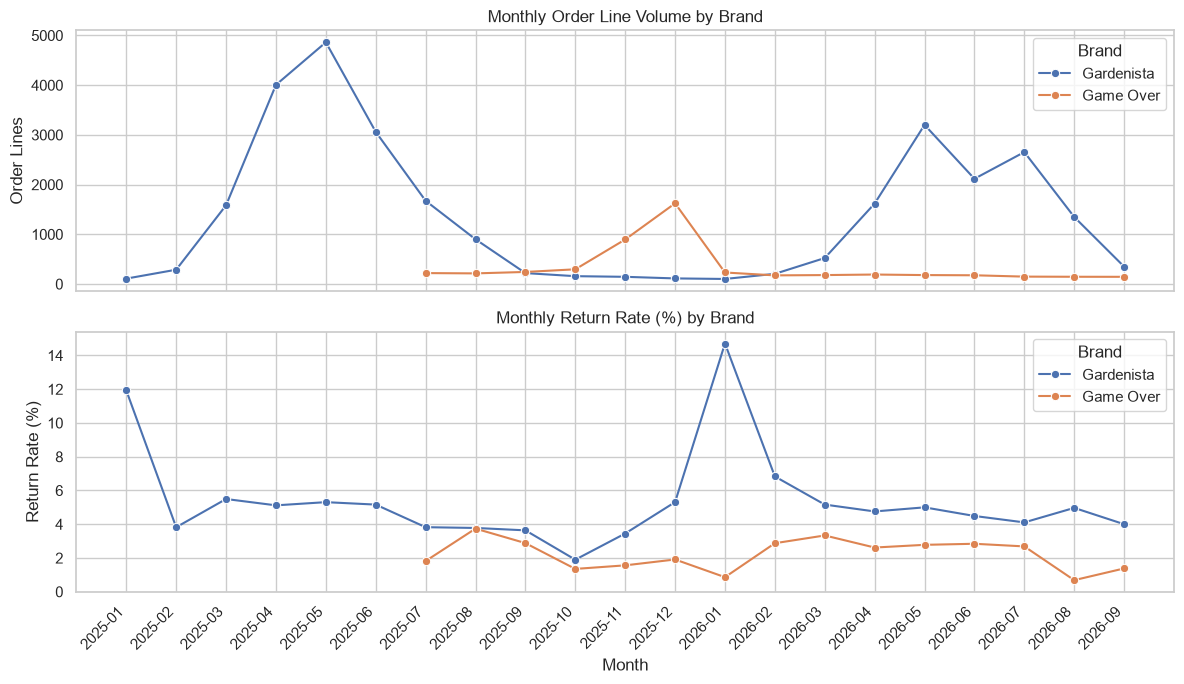

In [14]:
monthly_brand = (
    master_df.groupby(["Month", "Brand"], as_index=False)
    .agg(Lines=("Order ref", "count"), Return_Rate_Pct=("Returned", lambda s: s.mean() * 100))
)

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
sns.lineplot(data=monthly_brand, x="Month", y="Lines", hue="Brand", marker="o", ax=axes[0])
axes[0].set_title("Monthly Order Line Volume by Brand")
axes[0].set_ylabel("Order Lines")

sns.lineplot(data=monthly_brand, x="Month", y="Return_Rate_Pct", hue="Brand", marker="o", ax=axes[1])
axes[1].set_title("Monthly Return Rate (%) by Brand")
axes[1].set_ylabel("Return Rate (%)")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### 4.5 Courier Service & Line Value Distribution

Inspects return rates by `Courier service` (a strong unused predictor in the original notebook) and compares line values between returned and non-returned items.

,Courier service,Order_Lines,Return_Rate_Pct
2,DPD TWO DAY GUK,20821,4.6972
5,EVRI MAINLAND 48,4437,4.8907
3,Default,4300,4.3256
1,DPD TWO DAY GO,3350,2.0000
4,EVRI LIGHT AND LARGE,1351,5.4034
6,EVRI NEXT DAY,40,20.0000
0,BT Postcode - Do not Ship,6,66.6667


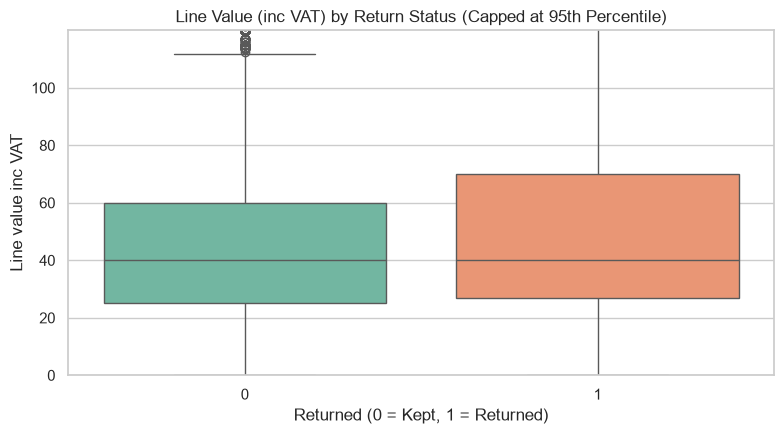

In [15]:
courier_eda = (
    master_df.groupby("Courier service", as_index=False)
    .agg(Order_Lines=("Order ref", "count"), Return_Rate_Pct=("Returned", lambda s: s.mean() * 100))
    .sort_values("Order_Lines", ascending=False)
)
display(courier_eda)

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.boxplot(data=master_df, x="Returned", y="Line value inc VAT", hue="Returned", palette="Set2", legend=False, ax=ax)
ax.set_ylim(0, master_df["Line value inc VAT"].quantile(0.95))
ax.set_title("Line Value (inc VAT) by Return Status (Capped at 95th Percentile)")
ax.set_xlabel("Returned (0 = Kept, 1 = Returned)")
plt.tight_layout()
plt.show()

### 4.6 Return Reasons, Scrap Rates & Financial Cost Breakdown

Analyzes `returns_df` by `Return reason` to identify which failure modes drive the highest return volume, scrap write-offs, and total cost.

,Return reason,Return_Count,Scrap_Rate_Pct,Avg_Days_To_Return,Total_Refunds,Total_Return_Cost
3,Faulty / poor quality,229,65.9389,17.2838,"11,297.0600","3,912.8100"
1,Damaged on arrival,173,87.8613,16.8150,"9,254.5300","3,796.3700"
7,Smell / stains,90,95.5556,16.3778,"5,150.6800","2,255.1700"
2,Does not fit,330,5.4545,17.4818,"18,401.4500","2,024.4400"
5,No longer needed,229,5.2402,16.0699,"11,895.7500","1,356.4300"
4,Item not as described / different to photos,217,4.6083,17.5300,"11,876.9500","1,312.7500"
6,Ordered by mistake,113,4.4248,18.6549,"4,937.7700",662.9400
0,Arrived too late,75,8.0000,17.1467,"3,364.1200",502.5500
8,Wrong item sent,67,16.4179,17.5224,"3,227.2500",493.8000


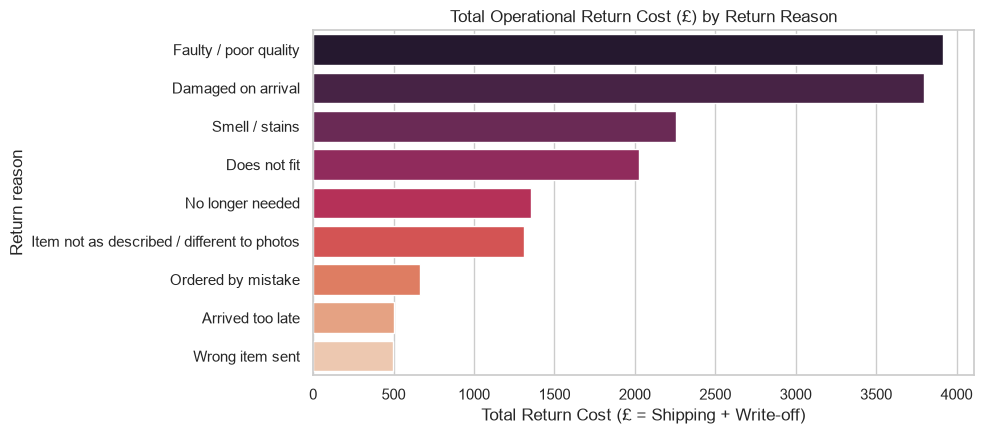

In [16]:
reason_eda = (
    returns_df.groupby("Return reason", as_index=False)
    .agg(
        Return_Count=("Order ref", "count"),
        Scrap_Rate_Pct=("Scrapped", lambda s: (s == "Yes").mean() * 100),
        Avg_Days_To_Return=("Days to return", "mean"),
        Total_Refunds=("Refund amount", "sum"),
        Total_Return_Cost=("Total return cost", "sum"),
    )
    .sort_values("Total_Return_Cost", ascending=False)
)
display(reason_eda)

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=reason_eda, y="Return reason", x="Total_Return_Cost", hue="Return reason", palette="rocket", legend=False, ax=ax)
ax.set_title("Total Operational Return Cost (£) by Return Reason")
ax.set_xlabel("Total Return Cost (£ = Shipping + Write-off)")
plt.tight_layout()
plt.show()

### 4.7 High-Volume High-Risk SKUs (Filtered View)

Inspects `returns_by_sku_df` flag distribution and filters to SKUs with at least `20` units sold so single-unit returns do not dominate risk rankings.

In [17]:
print("SKU Flag distribution (all 1,458 SKUs):")
display(returns_by_sku_df["Flag"].value_counts().rename_axis("Flag").to_frame("SKU Count"))

high_vol_risk = (
    returns_by_sku_df[returns_by_sku_df["Units sold"] >= 20]
    .assign(Return_Rate_Pct=lambda d: (1 - d["Kept rate"]) * 100)
    .sort_values(["Return_Rate_Pct", "Refund value"], ascending=False)
    .head(15)
)
print("Top 15 Highest Return-Rate SKUs (Units sold >= 20):")
display(high_vol_risk[["SKU", "Brand", "Units sold", "Units returned", "Return_Rate_Pct", "Flag", "Refund value"]])

SKU Flag distribution (all 1,458 SKUs):


,SKU Count
Flag,
Green,1380
Orange,45
Red,33


Top 15 Highest Return-Rate SKUs (Units sold >= 20):


,SKU,Brand,Units sold,Units returned,Return_Rate_Pct,Flag,Refund value
261,CS H1 Linoso Sand,Gardenista,40,23,57.5000,Red,298.3100
395,GP G1 PD Palm,Gardenista,25,8,32.0000,Orange,115.7600
316,PDG1 Duck Teal,Gardenista,33,10,30.3000,Orange,349.7000
219,GP G2 Two Part Pad B398 Grey 4pk,Gardenista,48,14,29.1700,Green,"1,111.6000"
280,LGP9 Harvest Stone,Gardenista,38,10,26.3200,Green,344.7000
432,CNP 2 Seater C6628 Green,Gardenista,23,6,26.0900,Green,124.8500
491,GP G77 Folding Harvest Green,Gardenista,20,5,25.0000,Green,224.9600
392,CC CD1 Arabesque Purple,Gardenista,25,6,24.0000,Green,59.9400
233,CS Malia Ikea Klippan Pacific,Gardenista,46,11,23.9100,Green,714.6700
468,PDG1 Duck Amber Gold,Gardenista,21,5,23.8100,Green,174.8400


# Module 5: Feature Engineering & Leak-Free Data Preparation

Construct strictly pre-purchase features, split by customer group (`train` / `val` / `test`) to prevent multi-line order and repeat-customer leakage, and build model-appropriate preprocessing pipelines.

### 5.1 Engineer Order, Product & Temporal Pre-Purchase Features

Creates features available **at checkout time** (zero post-return leakage):
- **Temporal:** month, day of week, weekend indicator
- **Basket context:** number of lines in the order, total order value, total order quantity, line share of order value
- **Product / Geo parsed from strings:** `sku_prefix` (product family), `pack_size` (parsed `2pk`, `4pk`, etc.), `is_bt_postcode` (Northern Ireland shipping-restriction indicator)

In [18]:
feat_df = master_df.copy()

# Temporal features
feat_df["order_month"] = feat_df["Order date"].dt.month
feat_df["order_dayofweek"] = feat_df["Order date"].dt.dayofweek
feat_df["is_weekend"] = (feat_df["order_dayofweek"] >= 5).astype(int)

# Basket / order-level features
order_agg = feat_df.groupby("Order ref").agg(
    order_line_count=("SKU", "count"),
    order_total_value=("Line value inc VAT", "sum"),
    order_total_qty=("Qty", "sum"),
)
feat_df = feat_df.merge(order_agg, on="Order ref", how="left")
feat_df["line_value_share"] = np.where(
    feat_df["order_total_value"] > 0,
    feat_df["Line value inc VAT"] / feat_df["order_total_value"],
    0.0,
)

# Product & UK postcode signals
feat_df["sku_prefix"] = feat_df["SKU"].str.split().str[0].fillna("OTHER")
pack_match = feat_df["SKU"].str.extract(r"(\d+)\s*[pP][kK]", expand=False)
feat_df["pack_size"] = pd.to_numeric(pack_match, errors="coerce").fillna(1).astype(int)
feat_df["is_bt_postcode"] = feat_df["Postcode area"].astype(str).str.upper().str.startswith("BT").astype(int)

print("Engineered feature table shape:", feat_df.shape)

Engineered feature table shape: (34305, 29)


### 5.2 Engineer Past-Only Customer Order History

Computes each customer's strictly prior order count (`cust_prior_orders`) and prior spend (`cust_prior_spend`) by aggregating to order level first, sorting chronologically, and shifting by one order.

- **Why:** Prevents any leakage across lines of the same order or from future orders.

In [19]:
order_hist = (
    feat_df.groupby(["Customer ref", "Order ref", "Order date"], as_index=False)
    .agg(order_val=("Line value inc VAT", "sum"))
    .sort_values(["Customer ref", "Order date", "Order ref"])
)

order_hist["cust_prior_orders"] = order_hist.groupby("Customer ref").cumcount()
order_hist["cust_prior_spend"] = (
    order_hist.groupby("Customer ref")["order_val"].cumsum() - order_hist["order_val"]
)

feat_df = feat_df.merge(
    order_hist[["Order ref", "cust_prior_orders", "cust_prior_spend"]],
    on="Order ref",
    how="left",
)
print("Customer prior order summary:")
display(feat_df[["cust_prior_orders", "cust_prior_spend"]].describe().T[["mean", "50%", "max"]])

Customer prior order summary:


,mean,50%,max
cust_prior_orders,0.6722,0.0000,11.0000
cust_prior_spend,32.7268,0.0000,877.1100


### 5.3 Customer-Grouped Train / Validation / Test Split (70% / 15% / 15%)

Partitions the dataset by **`Customer ref`** using `GroupShuffleSplit` so that:
1. No repeat customer or multi-line order appears in more than one split.
2. **Validation (`val`)** is used for early stopping and threshold tuning; **Test (`test`)** remains strictly untouched until final evaluation.

In [20]:
from sklearn.model_selection import GroupShuffleSplit

y_all = feat_df["Returned"].astype(int)
groups_all = feat_df["Customer ref"]

# First split off 15% held-out test set grouped by customer
gss_test = GroupShuffleSplit(n_splits=1, test_size=0.15, random_state=RANDOM_STATE)
trainval_idx, test_idx = next(gss_test.split(feat_df, y_all, groups=groups_all))

trainval_df = feat_df.iloc[trainval_idx].copy()
test_df = feat_df.iloc[test_idx].copy()

# Split remaining 85% into ~70% train and ~15% validation grouped by customer
gss_val = GroupShuffleSplit(n_splits=1, test_size=0.15 / 0.85, random_state=RANDOM_STATE)
tr_rel_idx, val_rel_idx = next(gss_val.split(trainval_df, trainval_df["Returned"], groups=trainval_df["Customer ref"]))

train_df = trainval_df.iloc[tr_rel_idx].copy()
val_df = trainval_df.iloc[val_rel_idx].copy()

for split_name, split_df in [("Train", train_df), ("Val", val_df), ("Test", test_df)]:
    print(f"{split_name:5s}: rows={len(split_df):5d} | customers={split_df['Customer ref'].nunique():5d} | return_rate={split_df['Returned'].mean()*100:.2f}%")

Train: rows=24137 | customers=15997 | return_rate=4.50%
Val  : rows= 5059 | customers= 3428 | return_rate=4.25%
Test : rows= 5109 | customers= 3429 | return_rate=4.54%


### 5.4 Out-of-Fold (OOF) Smoothed Target Encoding for High-Cardinality SKU

Encodes the 1,458 unique SKUs into a smoothed return risk (`sku_ret_rate_enc`, regularized with `m = 20`):
- **Training rows** are encoded **out-of-fold** via 5-fold `StratifiedGroupKFold` (grouped by `Customer ref`) so no row's own label leaks into its own feature (preventing severe target-encoding overfitting).
- **Validation & test rows** are mapped from the full `train_df` smoothed table.

In [21]:
from sklearn.model_selection import StratifiedGroupKFold

SMOOTHING_M = 20.0
global_prior = train_df["Returned"].mean()

# 5-fold customer-grouped out-of-fold encoding for train_df
oof_sku_enc = np.full(len(train_df), global_prior, dtype=float)
sgkf = StratifiedGroupKFold(n_splits=5)
for fold_tr, fold_va in sgkf.split(train_df, train_df["Returned"], groups=train_df["Customer ref"]):
    stats = train_df.iloc[fold_tr].groupby("SKU")["Returned"].agg(["count", "mean"])
    smoothed = (stats["count"] * stats["mean"] + SMOOTHING_M * global_prior) / (stats["count"] + SMOOTHING_M)
    oof_sku_enc[fold_va] = train_df.iloc[fold_va]["SKU"].map(smoothed).fillna(global_prior).to_numpy()

train_df["sku_ret_rate_enc"] = oof_sku_enc

# Full train_df mapping for val_df and test_df
full_stats = train_df.groupby("SKU")["Returned"].agg(["count", "mean"])
full_smoothed = (full_stats["count"] * full_stats["mean"] + SMOOTHING_M * global_prior) / (full_stats["count"] + SMOOTHING_M)
val_df["sku_ret_rate_enc"] = val_df["SKU"].map(full_smoothed).fillna(global_prior)
test_df["sku_ret_rate_enc"] = test_df["SKU"].map(full_smoothed).fillna(global_prior)

print(f"Global train prior: {global_prior:.4f} | OOF SKU range: {oof_sku_enc.min():.4f} to {oof_sku_enc.max():.4f}")

Global train prior: 0.0450 | OOF SKU range: 0.0031 to 0.2091


### 5.5 Define Feature Lists & Linear Preprocessor (Logistic Regression)

Separates categorical and numerical pre-purchase features and builds a `ColumnTransformer` (`OneHotEncoder(min_frequency=50)` for nominal categories + `StandardScaler` for numeric features only).

- **Why:** Prevents false ordinal ordering on nominal categories and groups rare `sku_prefix` values to reduce variance.

In [22]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

CAT_COLS = ["Brand", "Channel", "Courier service", "sku_prefix"]
NUM_COLS = [
    "Qty", "Unit price inc VAT", "Line value inc VAT", "Line_discount_clean",
    "Promotion applied", "Is_zero_value", "order_month", "order_dayofweek",
    "is_weekend", "order_line_count", "order_total_value", "order_total_qty",
    "line_value_share", "pack_size", "is_bt_postcode", "cust_prior_orders",
    "cust_prior_spend", "sku_ret_rate_enc",
]
FEATURE_COLS = CAT_COLS + NUM_COLS

X_train_raw, y_train = train_df[FEATURE_COLS], train_df["Returned"].astype(int).to_numpy()
X_val_raw, y_val = val_df[FEATURE_COLS], val_df["Returned"].astype(int).to_numpy()
X_test_raw, y_test = test_df[FEATURE_COLS], test_df["Returned"].astype(int).to_numpy()

preprocess_linear = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=50, sparse_output=False), CAT_COLS),
    ("num", StandardScaler(), NUM_COLS),
])

print(f"Configured {len(FEATURE_COLS)} features: {len(CAT_COLS)} categorical, {len(NUM_COLS)} numeric.")

Configured 22 features: 4 categorical, 18 numeric.


### 5.6 Encode Arrays for XGBoost & TabNet (Embedding-Safe Indices)

Maps categorical features strictly from `train_df` into safe `0..K` integer indices (reserving index `K` for unseen validation/test categories so PyTorch embeddings never crash):
- **`X_*_tab`**: integer categoricals + scaled numerics (`cat_idxs`, `cat_dims`, `cat_emb_dims`) for **TabNet**.
- **`X_*_tree`**: integer categoricals + raw unscaled numerics for **XGBoost**.

In [23]:
cat_dims = []
X_train_tab = np.zeros((len(train_df), len(FEATURE_COLS)), dtype=np.float32)
X_val_tab = np.zeros((len(val_df), len(FEATURE_COLS)), dtype=np.float32)
X_test_tab = np.zeros((len(test_df), len(FEATURE_COLS)), dtype=np.float32)

for idx, col in enumerate(CAT_COLS):
    cats = sorted(train_df[col].astype(str).unique())
    unk_idx = len(cats)
    mapping = {c: i for i, c in enumerate(cats)}
    cat_dims.append(unk_idx + 1)
    X_train_tab[:, idx] = train_df[col].astype(str).map(mapping).fillna(unk_idx).to_numpy()
    X_val_tab[:, idx] = val_df[col].astype(str).map(mapping).fillna(unk_idx).to_numpy()
    X_test_tab[:, idx] = test_df[col].astype(str).map(mapping).fillna(unk_idx).to_numpy()

num_scaler = StandardScaler()
X_train_tab[:, len(CAT_COLS):] = num_scaler.fit_transform(train_df[NUM_COLS])
X_val_tab[:, len(CAT_COLS):] = num_scaler.transform(val_df[NUM_COLS])
X_test_tab[:, len(CAT_COLS):] = num_scaler.transform(test_df[NUM_COLS])

cat_idxs = list(range(len(CAT_COLS)))
cat_emb_dims = [min(16, max(2, (d + 1) // 2)) for d in cat_dims]

X_train_tree, X_val_tree, X_test_tree = X_train_tab.copy(), X_val_tab.copy(), X_test_tab.copy()
X_train_tree[:, len(CAT_COLS):] = train_df[NUM_COLS].to_numpy(dtype=np.float32)
X_val_tree[:, len(CAT_COLS):] = val_df[NUM_COLS].to_numpy(dtype=np.float32)
X_test_tree[:, len(CAT_COLS):] = test_df[NUM_COLS].to_numpy(dtype=np.float32)

print("TabNet cat_dims:", cat_dims, "| embedding dims:", cat_emb_dims)

TabNet cat_dims: [3, 9, 8, 46] | embedding dims: [2, 5, 4, 16]


# Module 6: Imbalance-Aware Model Training & Threshold Tuning

Train Logistic Regression, XGBoost, and TabNet with explicit class-imbalance handling, validation-only early stopping, and validation-tuned classification thresholds.

### 6.1 Validation Threshold Tuner & Evaluation Utility

Defines two reusable helper functions:
- `tune_threshold(y_val, val_probs)`: chooses the probability cutoff that maximizes **Class-1 F1** on the validation set (never touching test labels).
- `evaluate_model(...)`: prints classification report and returns a structured metrics dictionary including **ROC-AUC** and **PR-AUC** (essential for imbalanced datasets).

In [24]:
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    f1_score,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
)

def tune_threshold(y_true, probs):
    prec, rec, thresholds = precision_recall_curve(y_true, probs)
    f1s = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    best_idx = int(np.argmax(f1s))
    return float(thresholds[best_idx])

def evaluate_model(name, y_true, probs, threshold):
    preds = (probs >= threshold).astype(int)
    print(f"=== {name} (Test Set | threshold={threshold:.3f}) ===")
    print(classification_report(y_true, preds, zero_division=0))
    return {
        "Model": name,
        "Threshold": round(threshold, 4),
        "ROC_AUC": round(roc_auc_score(y_true, probs), 4),
        "PR_AUC": round(average_precision_score(y_true, probs), 4),
        "Precision_1": round(precision_score(y_true, preds, zero_division=0), 4),
        "Recall_1": round(recall_score(y_true, preds, zero_division=0), 4),
        "F1_1": round(f1_score(y_true, preds, zero_division=0), 4),
    }

model_results = []
test_prob_store = {}

### 6.2 Model 1 — Balanced Logistic Regression

Trains an L2-regularized Logistic Regression pipeline with `class_weight='balanced'` and `OneHotEncoder` so nominal categories are modeled accurately and minority returns are weighted properly.

In [25]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

lr_pipeline = Pipeline([
    ("prep", preprocess_linear),
    ("clf", LogisticRegression(class_weight="balanced", max_iter=1000, C=1.0, random_state=RANDOM_STATE)),
])
lr_pipeline.fit(X_train_raw, y_train)

lr_val_probs = lr_pipeline.predict_proba(X_val_raw)[:, 1]
lr_test_probs = lr_pipeline.predict_proba(X_test_raw)[:, 1]
lr_thresh = tune_threshold(y_val, lr_val_probs)

model_results.append(evaluate_model("Logistic Regression (Balanced)", y_test, lr_test_probs, lr_thresh))
test_prob_store["Logistic Regression"] = lr_test_probs

=== Logistic Regression (Balanced) (Test Set | threshold=0.629) ===
              precision    recall  f1-score   support

           0       0.96      0.89      0.92      4877
           1       0.09      0.23      0.13       232

    accuracy                           0.86      5109
   macro avg       0.53      0.56      0.53      5109
weighted avg       0.92      0.86      0.89      5109



### 6.3 Model 2 — Imbalance-Weighted XGBoost Classifier

Trains an `XGBClassifier` weighted by `scale_pos_weight = negatives / positives`, using **validation-set early stopping** (`eval_set=[(X_val_tree, y_val)]`) so test data never leaks into tree count selection.

In [26]:
from xgboost import XGBClassifier

neg_pos_ratio = float((y_train == 0).sum() / max((y_train == 1).sum(), 1))

xgb_model = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=neg_pos_ratio,
    eval_metric="aucpr",
    early_stopping_rounds=25,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
xgb_model.fit(
    X_train_tree,
    y_train,
    eval_set=[(X_val_tree, y_val)],
    verbose=False,
)

xgb_val_probs = xgb_model.predict_proba(X_val_tree)[:, 1]
xgb_test_probs = xgb_model.predict_proba(X_test_tree)[:, 1]
xgb_thresh = tune_threshold(y_val, xgb_val_probs)

model_results.append(evaluate_model("XGBoost (Weighted)", y_test, xgb_test_probs, xgb_thresh))
test_prob_store["XGBoost"] = xgb_test_probs

=== XGBoost (Weighted) (Test Set | threshold=0.519) ===
              precision    recall  f1-score   support

           0       0.96      0.96      0.96      4877
           1       0.11      0.11      0.11       232

    accuracy                           0.92      5109
   macro avg       0.54      0.53      0.53      5109
weighted avg       0.92      0.92      0.92      5109



### 6.4 Model 3 — TabNet Classifier (Embeddings + Validation Early Stopping)

Trains a deep tabular attention network (`TabNetClassifier`) with:
- Proper learned embeddings (`cat_idxs`, `cat_dims`, `cat_emb_dim`) instead of scaling categorical IDs
- Built-in balanced sampling (`weights=1`) for the 4.5% positive class
- Early stopping strictly on **`X_val_tab, y_val`** (eliminating the test-set leakage from the original notebook)

In [27]:
from pytorch_tabnet.tab_model import TabNetClassifier

tabnet_model = TabNetClassifier(
    cat_idxs=cat_idxs,
    cat_dims=cat_dims,
    cat_emb_dim=cat_emb_dims,
    seed=RANDOM_STATE,
    verbose=1,
)
tabnet_model.fit(
    X_train=X_train_tab,
    y_train=y_train,
    eval_set=[(X_val_tab, y_val)],
    eval_name=["val"],
    eval_metric=["auc"],
    weights=1,
    max_epochs=30,
    patience=7,
    batch_size=1024,
    virtual_batch_size=128,
)

tab_val_probs = tabnet_model.predict_proba(X_val_tab)[:, 1]
tab_test_probs = tabnet_model.predict_proba(X_test_tab)[:, 1]
tab_thresh = tune_threshold(y_val, tab_val_probs)

model_results.append(evaluate_model("TabNet (Embeddings + Balanced)", y_test, tab_test_probs, tab_thresh))
test_prob_store["TabNet"] = tab_test_probs

epoch 0  | loss: 0.74194 | val_auc: 0.59747 |  0:00:02s


epoch 1  | loss: 0.66439 | val_auc: 0.58258 |  0:00:03s


epoch 2  | loss: 0.66015 | val_auc: 0.60332 |  0:00:05s


epoch 3  | loss: 0.65068 | val_auc: 0.61383 |  0:00:07s


epoch 4  | loss: 0.64374 | val_auc: 0.61109 |  0:00:10s


epoch 5  | loss: 0.63885 | val_auc: 0.60916 |  0:00:12s


... (2 outputs left out)

epoch 8  | loss: 0.63177 | val_auc: 0.60456 |  0:00:20s


epoch 9  | loss: 0.62709 | val_auc: 0.60563 |  0:00:23s


epoch 10 | loss: 0.62251 | val_auc: 0.6106  |  0:00:25s

Early stopping occurred at epoch 10 with best_epoch = 3 and best_val_auc = 0.61383


=== TabNet (Embeddings + Balanced) (Test Set | threshold=0.611) ===
              precision    recall  f1-score   support

           0       0.96      0.89      0.92      4877
           1       0.08      0.19      0.11       232

    accuracy                           0.85      5109
   macro avg       0.52      0.54      0.51      5109
weighted avg       0.92      0.85      0.88      5109



# Module 7: Model Comparison, Interpretability & Takeaways

Benchmark all three models on the held-out test set, plot ROC and Precision-Recall curves, inspect top return-risk predictors, and summarize business recommendations.

### 7.1 Side-by-Side Test Performance Leaderboard

Consolidates ROC-AUC, PR-AUC, Class-1 Precision, Recall, and F1 across all models sorted by **PR-AUC** (the most informative ranking metric under 4.5% class imbalance).

In [28]:
results_df = pd.DataFrame(model_results).sort_values("PR_AUC", ascending=False).reset_index(drop=True)
display(results_df)

,Model,Threshold,ROC_AUC,PR_AUC,Precision_1,Recall_1,F1_1
0,Logistic Regression (Balanced),0.6285,0.6208,0.0858,0.0904,0.2284,0.1296
1,XGBoost (Weighted),0.5186,0.5949,0.0767,0.1136,0.1078,0.1106
2,TabNet (Embeddings + Balanced),0.6106,0.5947,0.0654,0.0751,0.1940,0.1083


### 7.2 ROC & Precision-Recall Curves Comparison

Plots test-set ROC and Precision-Recall curves together so you can visually compare ranking lift against the `4.5%` random-baseline return rate.

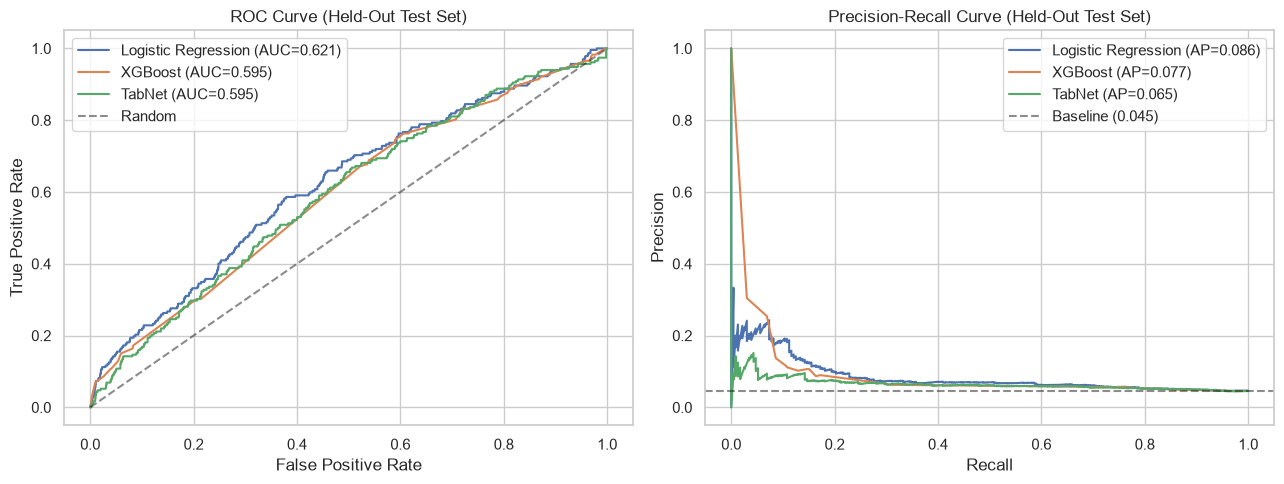

In [29]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for name, probs in test_prob_store.items():
    fpr, tpr, _ = roc_curve(y_test, probs)
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, probs):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, probs)
    axes[1].plot(rec, prec, label=f"{name} (AP={average_precision_score(y_test, probs):.3f})")

axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random")
axes[0].set_title("ROC Curve (Held-Out Test Set)")
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].legend()

baseline_rate = y_test.mean()
axes[1].axhline(baseline_rate, color="k", linestyle="--", alpha=0.5, label=f"Baseline ({baseline_rate:.3f})")
axes[1].set_title("Precision-Recall Curve (Held-Out Test Set)")
axes[1].set_xlabel("Recall")
axes[1].set_ylabel("Precision")
axes[1].legend()

plt.tight_layout()
plt.show()

### 7.3 Top Feature Importances (XGBoost)

Extracts and visualizes the top 15 predictors driving XGBoost's return-risk scores to translate model performance into operational levers.

,Feature,Importance
3,sku_prefix,0.1882
0,Brand,0.0913
21,sku_ret_rate_enc,0.0863
16,line_value_share,0.0513
15,order_total_qty,0.0479
2,Courier service,0.0446
5,Unit price inc VAT,0.0434
6,Line value inc VAT,0.0418
10,order_month,0.0418
12,is_weekend,0.0416


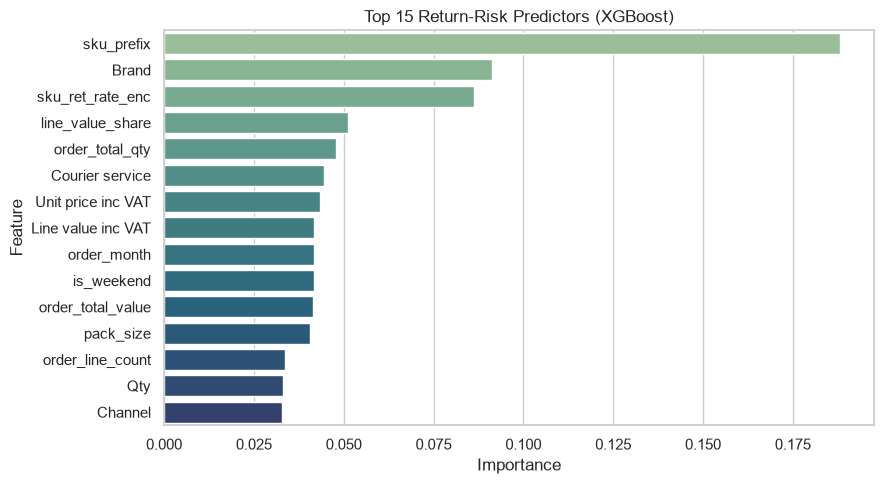

In [30]:
imp_df = (
    pd.DataFrame({"Feature": FEATURE_COLS, "Importance": xgb_model.feature_importances_})
    .sort_values("Importance", ascending=False)
    .head(15)
)
display(imp_df)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=imp_df, y="Feature", x="Importance", hue="Feature", palette="crest", legend=False, ax=ax)
ax.set_title("Top 15 Return-Risk Predictors (XGBoost)")
plt.tight_layout()
plt.show()

### 7.4 Summary & Actionable Business Recommendations

Based on the audited data and modular modeling workflow:

1. **Prioritize *Gardenista* Fit & Product-Description Accuracy:** *Gardenista* has more than double the return rate of *Game Over* (`4.89%` vs. `2.03%`), and **`Does not fit` (330)** plus **`Item not as described / different to photos` (217)** account for over a third of all recorded returns. Adding dimensional fit guides and accurate color/scale photography directly targets the highest-volume return drivers.
2. **Target High-Scrap Failure Modes to Cut Write-Off Costs:** While `Damaged on arrival` (`173`), `Faulty / poor quality` (`229`), and `Smell / stains` (`90`) represent ~32% of return volume, they drive the overwhelming majority of scrapped inventory (`88%`, `66%`, and `96%` scrap rates respectively) and write-off losses (£8,367 total).
3. **Audit High-Risk Couriers & Channels:** Investigate `EVRI NEXT DAY` (`20.0%` return rate, `n=40`), `BT Postcode - Do not Ship` exceptions (`66.7%`, `n=6`), `The Range` (`6.47%`), and `TikTok Shop` (`6.73%`, including 5 returned lines with £0 refund despite non-zero prices).
4. **Fix Upstream Data Hygiene:** Reconcile the 10 £0-value returned lines absent from `Returns.xlsx`, cap `Line discount` exports at `100%` (currently `200` on 3 two-unit rows), and review the 2 partial-unit returns that issued 100% full-line refunds.